https://proproprogs.ru/nn_pytorch/pytorch-dvunapravlennye-rnn-v-pytorch-sentiment-analiz-fraz

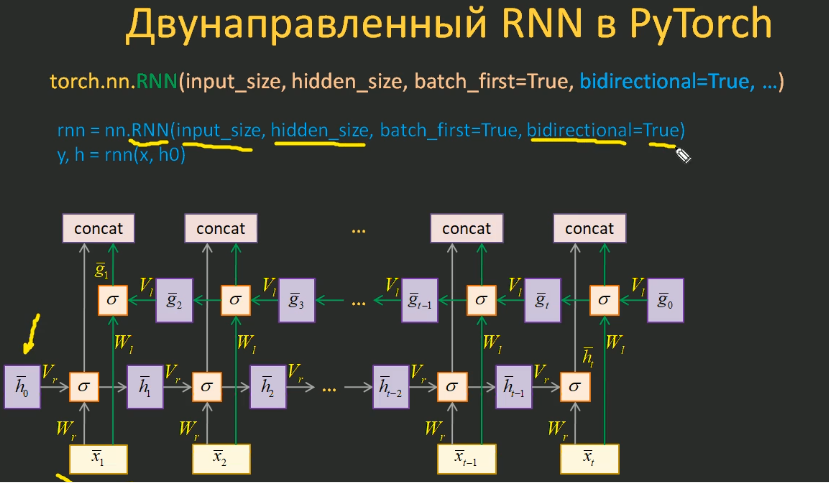

на выходе мы получаем y - это вектор сконкатенированных выходов прямого и обратного прохода, и h - это сконкатенированные векторы последних элементов последовательности при прямом и обратном проходе

In [29]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim
import re
from tqdm import tqdm

rnn = nn.RNN(300, 16, batch_first=True, bidirectional=True) # input_size, hidden_size

x = torch.randn(8, 3, 300) # batch_size, seq_length, input_size
y, h = rnn(x)

print('y:', y.size()) # batch_size, seq_length, 2*hidden_size
print('h:', h.size()) # число последних векторов скрытого состояния (1 при прямом + 1 при обратном проходе), batch_size, hidden_size

y: torch.Size([8, 3, 32])
h: torch.Size([2, 8, 16])


решаем задачку сентимента-анализа

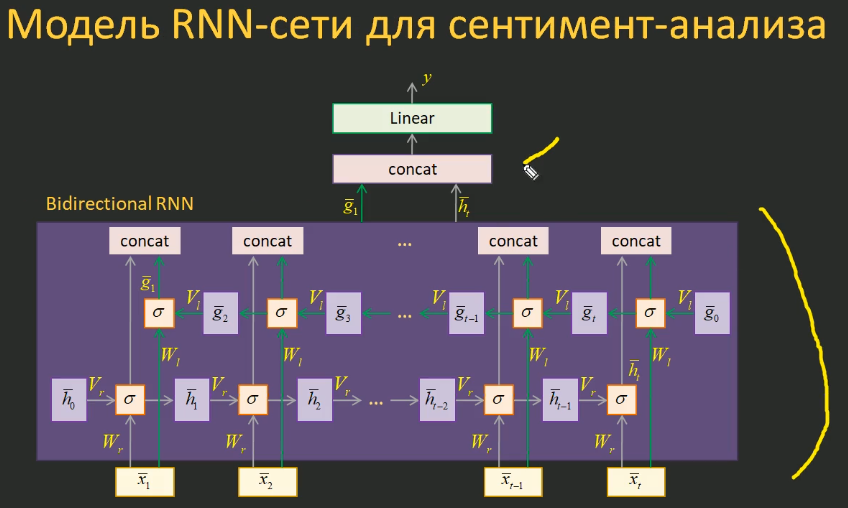

In [2]:
class WordsRNN(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.hidden_size = 16
        self.in_features = in_features
        self.out_features = out_features
 
        self.rnn = nn.RNN(in_features, self.hidden_size, batch_first=True, bidirectional=True)
        self.out = nn.Linear(self.hidden_size * 2, out_features)
 
    def forward(self, x):
        x, h = self.rnn(x)
        hh = torch.cat((h[-2, :, :], h[-1, :, :]), dim=1) # по идее это можно реализовать через reshape
        y = self.out(hh)
        return y

все фразы имеют разную длину. а так как внутри батча последовательность должна иметь одинаковую длину, короткие фразы нужно добить нулями. То есть в общем случае нужно принять за длину размер самой длинной фразы, но тогда для коротких потребуется добивать слишком много. Поэтому мы отсортируем фразы по длине и в батч будем объединять схожие по размеру фразы

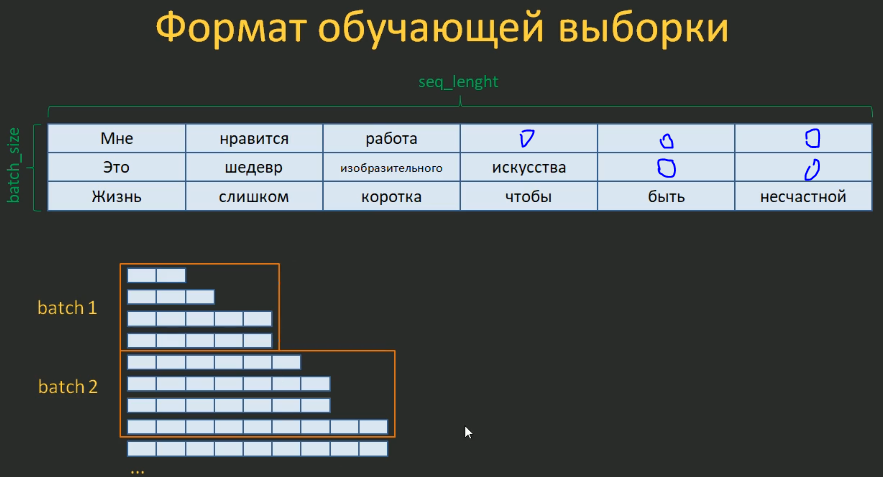

In [12]:
class PhraseDataset(data.Dataset):
    def __init__(self, path_true, path_false, navec_emb, batch_size=8):
        self.navec_emb = navec_emb
        # размер батча укажем здесь, то есть элементом датасета будет уже батч, а в даталоадере укажем размер батча = 1
        self.batch_size = batch_size 
 
        with open(path_true, 'r', encoding='utf-8') as f:
            phrase_true = f.readlines()
            self._clear_phrase(phrase_true)
 
        with open(path_false, 'r', encoding='utf-8') as f:
            phrase_false = f.readlines()
            self._clear_phrase(phrase_false)
 
        self.phrase_lst = [(_x, 0) for _x in phrase_true] + [(_x, 1) for _x in phrase_false]
        self.phrase_lst.sort(key=lambda _x: len(_x[0]))
        self.dataset_len = len(self.phrase_lst)
 
    def _clear_phrase(self, p_lst):
        for _i, _p in enumerate(p_lst):
            _p = _p.lower().replace('\ufeff', '').strip()
            _p = re.sub(r'[^А-яA-z- ]', '', _p)
            _words = _p.split()
            _words = [w for w in _words if w in self.navec_emb]
            p_lst[_i] = _words
 
    def __getitem__(self, item):
        item *= self.batch_size
        item_last = item + self.batch_size
        if item_last > self.dataset_len:
            item_last = self.dataset_len
 
        _data = []
        _target = []
        max_length = len(self.phrase_lst[item_last-1][0])
 
        for i in range(item, item_last):
            words_emb = []
            phrase = self.phrase_lst[i]
            length = len(phrase[0])
 
            for k in range(max_length):
                t = torch.tensor(self.navec_emb[phrase[0][k]], dtype=torch.float32) if k < length else torch.zeros(300)
                words_emb.append(t)
 
            _data.append(torch.vstack(words_emb))
            _target.append(torch.tensor(phrase[1], dtype=torch.float32))
 
        _data_batch = torch.stack(_data)
        _target = torch.vstack(_target)
        return _data_batch, _target
 
    def __len__(self):
        last = 0 if self.dataset_len % self.batch_size == 0 else 1
        return self.dataset_len // self.batch_size + last

In [13]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [14]:
d_train = PhraseDataset("train_data_true.txt", "train_data_false.txt", navec)
train_data = data.DataLoader(d_train, batch_size=1, shuffle=True)
 
model = WordsRNN(300, 1)

In [17]:
optimizer = optim.Adam(params=model.parameters(), lr=0.001, weight_decay=0.001)
loss_func = nn.BCEWithLogitsLoss()
 
epochs = 20
model.train()

WordsRNN(
  (rnn): RNN(300, 16, batch_first=True, bidirectional=True)
  (out): Linear(in_features=32, out_features=1, bias=True)
)

In [25]:
for _e in range(epochs):
    loss_mean = 0
    lm_count = 0
 
    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict = model(x_train.squeeze(0)).squeeze(0)
        loss = loss_func(predict, y_train.squeeze(0))
 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
 
        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

Epoch [20/20], loss_mean=0.004: 100%|██████████| 22/22 [00:00<00:00, 89.68it/s]


In [26]:
st = model.state_dict()
torch.save(st, 'model_rnn_bidir.tar')

In [28]:
model.eval()

phrase = "Сегодня пасмурная погода"
phrase_lst = phrase.lower().split()
phrase_lst = [torch.tensor(navec[w]) for w in phrase_lst if w in navec]
_data_batch = torch.stack(phrase_lst)
predict = model(_data_batch.unsqueeze(0)).squeeze(0)
p = torch.nn.functional.sigmoid(predict).item()
print(p)
print(phrase, ":", "положительное" if p < 0.5 else "негативное")

0.5607649087905884
Сегодня пасмурная погода : негативное
